# Case Trainee Quant — Estratégia de Momentum 12-1 na B3

Carteira long-only que, todo mês, compra as **5 ações com maior momentum 12-1** de um universo fixo de 20 ações da B3,
com pesos iguais, rebalanceamento mensal e sem custos, comparada com o **Ibovespa** de jan/2016 a dez/2025.

$$\text{MOM}_{i,t} = \frac{P_{i,t-1}}{P_{i,t-12}} - 1$$

**Roteiro:** 0. Configuração · 1. Dados · 2. Sinal · 3. Carteira · 4. Métricas · 5. Gráficos · 6. Respostas · 7. Limitações

## 0. Configuração

Todos os parâmetros do case ficam nesta célula.

- **`WARMUP = True`**: o sinal 12-1 precisa de 12 meses de histórico. Para a carteira existir já em **jan/2016**,
  os pesos são decididos no fim de **dez/2015**, e o sinal dessa data usa $P_{t-12}$ = preço de **dez/2014**.
  Por isso o download começa em **2014-12-01**. Esses 13 meses servem só para aquecer o sinal e não entram
  em nenhuma métrica. *(Observação: começar o download em 2015-01 não bastaria, porque faltaria o preço de
  dez/2014 e a primeira carteira só sairia em fev/2016.)* Com `WARMUP = False`, o download começa em 2016-01
  e a carteira só existe a partir de fev/2017.
- **`FORCE_DOWNLOAD = False`**: reutiliza o cache em `data/` para que o resultado seja reprodutível e não dependa da rede.
- **`YF_ALIAS`**: a Embraer trocou o código **EMBR3 → EMBJ3** na B3 em 2025, e o Yahoo Finance não responde mais por
  `EMBR3.SA` (404, *possibly delisted*). O histórico da mesma empresa existe completo em `EMBJ3.SA`, então ele é baixado
  nesse código e tratado como EMBR3. Nenhum dado é preenchido ou inventado; isso aparece na tabela de qualidade abaixo.
  Para ver o comportamento sem o alias, use `YF_ALIAS = {}`: a EMBR3 fica sem dados e é excluída do ranking.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import ListedColormap
import yfinance as yf
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Universo e benchmark
TICKERS = ["PETR4", "VALE3", "ITUB4", "BBDC4", "BBAS3", "ABEV3", "WEGE3", "B3SA3", "RENT3", "SUZB3",
           "GGBR4", "EMBR3", "EQTL3", "RADL3", "LREN3", "PRIO3", "VIVT3", "CMIG4", "SBSP3", "TOTS3"]
BENCHMARK = "^BVSP"
YF_ALIAS = {"EMBR3": "EMBJ3"}       # código renomeado na B3; o histórico está no código novo

# --- Estratégia e período
ANALYSIS_START = "2016-01-01"
ANALYSIS_END = "2025-12-31"
TOP_N = 5
WARMUP = True
FORCE_DOWNLOAD = False
CDI_SGS_CODE = 4391                  # CDI acumulado no mês, % (SGS/BCB)

DOWNLOAD_START = "2014-12-01" if WARMUP else ANALYSIS_START
DOWNLOAD_END = "2026-01-01"          # exclusivo no yfinance

DATA_DIR, FIG_DIR = Path("data"), Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
PRICES_CACHE = DATA_DIR / f"precos_diarios_desde_{DOWNLOAD_START[:7]}.csv"
CDI_CACHE = DATA_DIR / "cdi_mensal_sgs4391.csv"

# --- Estilo dos gráficos
C_PORT, C_IBOV, C_NEG = "#2a78d6", "#eb6834", "#e34948"
C_TEXT, C_GRID = "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (11, 4.8), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_TEXT, "xtick.color": C_TEXT, "ytick.color": C_TEXT,
    "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False, "lines.linewidth": 2,
})

## 1. Dados

1. `load_prices` baixa os preços diários de fechamento **ajustados** (`auto_adjust=True`, coluna `Close`, já corrigida por
   proventos e desdobramentos) e salva/lê o cache em `data/`.
2. `monthly_prices` mensaliza pelo **último preço disponível de cada mês** (`resample("ME").last()`).
3. `data_quality_report` lista, por ticker, a primeira e a última data válidas, o % de pregões sem preço e os maiores movimentos,
   com alertas automáticos. Uma ação sem preço num mês **não entra no ranking** daquele mês, porque nada é preenchido com dado futuro.

In [2]:
def yf_symbol(ticker):
    return YF_ALIAS.get(ticker, ticker) + ".SA"


def download_prices(tickers, benchmark, start, end):
    symbol_to_name = {yf_symbol(t): t for t in tickers} | {benchmark: benchmark}
    raw = yf.download(list(symbol_to_name), start=start, end=end, auto_adjust=True, progress=False)
    close = raw["Close"].rename(columns=symbol_to_name)
    return close.reindex(columns=list(symbol_to_name.values()))


def load_prices(tickers, benchmark, start, end, cache, force=False):
    if cache.exists() and not force:
        cached = pd.read_csv(cache, index_col=0, parse_dates=True)
        if set(tickers + [benchmark]) <= set(cached.columns):
            return cached[tickers + [benchmark]], f"cache ({cache})"
    prices = download_prices(tickers, benchmark, start, end)
    prices.to_csv(cache)
    return prices, "yfinance (cache salvo)"


def monthly_prices(daily):
    return daily.resample("ME").last()


def monthly_returns(prices):
    return prices.pct_change(fill_method=None)


def br(text):
    # Separadores no padrão brasileiro: 1,234.5 -> 1.234,5
    return text.replace(",", "\0").replace(".", ",").replace("\0", ".")


def pct(x, digits=1, sign=False):
    return br(f"{x:{'+' if sign else ''},.{digits}%}")


def sim_nao(flag):
    return "Sim" if flag else "Não"

In [3]:
daily, source = load_prices(TICKERS, BENCHMARK, DOWNLOAD_START, DOWNLOAD_END, PRICES_CACHE, FORCE_DOWNLOAD)
monthly = monthly_prices(daily)

display(Markdown(
    f"**Fonte:** {source} · **Pregões:** {br(f'{len(daily):,}')} ({daily.index.min():%d/%m/%Y} a {daily.index.max():%d/%m/%Y}) · "
    f"**Meses:** {len(monthly)} ({monthly.index.min():%m/%Y} a {monthly.index.max():%m/%Y})"
))

**Fonte:** cache (data\precos_diarios_desde_2014-12.csv) · **Pregões:** 2.757 (01/12/2014 a 30/12/2025) · **Meses:** 133 (12/2014 a 12/2025)

In [4]:
def first_and_last_valid(s):
    return s.first_valid_index(), s.last_valid_index()


def quality_alerts(name, s, daily_rets, start):
    first, _ = first_and_last_valid(s)
    if first is None:
        return "SEM DADOS no Yahoo: excluído do ranking"
    alerts = []
    if first > start + pd.Timedelta(days=10):
        alerts.append("histórico começa depois do início")
    if s.loc[first:].isna().mean() > 0.02:
        alerts.append("buracos > 2% dos pregões")
    if daily_rets.abs().max() > 0.30:
        alerts.append("variação diária > 30% (verificar)")
    if name in YF_ALIAS:
        alerts.append(f"baixado como {YF_ALIAS[name]}.SA (código renomeado)")
    return "; ".join(alerts) or "ok"


def data_quality_report(daily, monthly):
    m_rets, d_rets = monthly_returns(monthly), daily.pct_change(fill_method=None)
    rows = {}
    for name in daily.columns:
        s, mr = daily[name], m_rets[name].dropna()
        first, last = first_and_last_valid(s)
        rows[name] = {
            "Símbolo Yahoo": name if name.startswith("^") else yf_symbol(name),
            "1ª data válida": first.date() if first is not None else None,
            "Última data válida": last.date() if last is not None else None,
            "% pregões sem preço": s.loc[first:].isna().mean() if first is not None else 1.0,
            "Meses com preço": int(monthly[name].notna().sum()),
            "Maior alta mensal": mr.max() if len(mr) else np.nan,
            "Mês da alta": f"{mr.idxmax():%m/%Y}" if len(mr) else None,
            "Maior queda mensal": mr.min() if len(mr) else np.nan,
            "Mês da queda": f"{mr.idxmin():%m/%Y}" if len(mr) else None,
            "Maior var. diária (abs)": d_rets[name].abs().max(),
            "Alertas": quality_alerts(name, s, d_rets[name], daily.index[0]),
        }
    return pd.DataFrame(rows).T


def format_pct(df, cols, digits=1):
    out = df.copy()
    for c in cols:
        out[c] = out[c].map(lambda x: "—" if pd.isna(x) else pct(x, digits))
    return out


quality = data_quality_report(daily, monthly)
display(format_pct(quality, ["% pregões sem preço", "Maior alta mensal", "Maior queda mensal", "Maior var. diária (abs)"]))

,Símbolo Yahoo,1ª data válida,Última data válida,% pregões sem preço,Meses com preço,Maior alta mensal,Mês da alta,Maior queda mensal,Mês da queda,Maior var. diária (abs),Alertas
PETR4,PETR4.SA,2014-12-01,2025-12-30,"0,0%",133,"61,7%",03/2016,"-44,8%",03/2020,"29,7%",ok
VALE3,VALE3.SA,2014-12-01,2025-12-30,"0,0%",133,"30,4%",04/2015,"-27,8%",05/2016,"24,6%",ok
ITUB4,ITUB4.SA,2014-12-01,2025-12-30,"0,0%",133,"22,9%",03/2016,"-27,8%",03/2020,"18,0%",ok
BBDC4,BBDC4.SA,2014-12-01,2025-12-30,"0,0%",133,"26,9%",03/2016,"-31,9%",03/2020,"17,4%",ok
BBAS3,BBAS3.SA,2014-12-01,2025-12-30,"0,0%",133,"47,5%",03/2016,"-40,2%",03/2020,"21,2%",ok
ABEV3,ABEV3.SA,2014-12-01,2025-12-30,"0,0%",133,"20,1%",05/2021,"-18,5%",02/2020,"15,8%",ok
WEGE3,WEGE3.SA,2014-12-01,2025-12-30,"0,0%",133,"33,3%",07/2020,"-22,1%",03/2020,"20,6%",ok
B3SA3,B3SA3.SA,2014-12-01,2025-12-30,"0,0%",133,"32,1%",03/2016,"-24,0%",03/2020,"19,2%",ok
RENT3,RENT3.SA,2014-12-01,2025-12-30,"0,0%",133,"30,0%",04/2020,"-46,8%",03/2020,"26,8%",ok
SUZB3,SUZB3.SA,2014-12-01,2025-12-30,"0,0%",133,"53,4%",03/2018,"-21,3%",10/2018,"21,8%",ok


**Leitura da tabela.** Os maiores movimentos mensais caem em **mar/2016** (rali do processo de impeachment) e **mar/2020**
(crash da COVID), que são eventos reais de mercado e não erros de dados. A **PRIO3** tem dias com variação acima de 30% em 2015–2016,
coerente com o fato de a então PetroRio ser uma ação de poucos centavos e baixa liquidez naquela época. Esses dados foram
**mantidos como vieram**, mas o ponto é retomado na resposta 2 e nas limitações.

### Checagem do Ibovespa (`^BVSP`)
O Yahoo às vezes entrega o índice em outra escala (por exemplo, dividido por 1.000) ou com dias faltando. A célula abaixo verifica
o nível, saltos impossíveis e buracos antes de usar a série.

In [5]:
def benchmark_check(daily_bench, monthly_bench, analysis_start, analysis_end):
    d_ret = daily_bench.pct_change(fill_method=None).dropna()
    window = monthly_bench.loc[analysis_start:analysis_end]
    checks = {
        "Nível mínimo (pontos)": br(f"{daily_bench.min():,.0f}"),
        "Nível máximo (pontos)": br(f"{daily_bench.max():,.0f}"),
        "Maior variação diária (abs)": f"{pct(d_ret.abs().max())} em {d_ret.abs().idxmax():%d/%m/%Y}",
        "Pregões das ações sem cotação do índice": f"{daily_bench.isna().sum()} de {br(f'{len(daily_bench):,}')}",
        "Meses do período de análise sem preço": int(window.isna().sum()),
    }
    # Escala plausível para o Ibovespa (dezenas de milhares de pontos) e nenhum salto de escala
    assert 30_000 < daily_bench.min() and daily_bench.max() < 300_000, "Ibovespa fora da escala esperada"
    assert d_ret.abs().max() < 0.25, "salto diário suspeito no Ibovespa (mudança de escala?)"
    assert window.notna().all(), "mês sem preço do Ibovespa no período de análise"
    return pd.Series(checks, name="Ibovespa").to_frame()


display(benchmark_check(daily[BENCHMARK], monthly[BENCHMARK], ANALYSIS_START, ANALYSIS_END))

,Ibovespa
Nível mínimo (pontos),37.497
Nível máximo (pontos),164.456
Maior variação diária (abs),"14,8% em 12/03/2020"
Pregões das ações sem cotação do índice,8 de 2.757
Meses do período de análise sem preço,0


O índice está na escala correta (dezenas de milhares de pontos) e não tem saltos de escala. Os poucos pregões sem cotação são dias em que
o Yahoo não publicou o índice. Como a mensalização usa o **último preço válido do mês**, esses buracos não afetam a série mensal,
que está completa em todo o período de análise.

## 2. Sinal: momentum 12-1 sem look-ahead

**Convenção:** cada linha do DataFrame mensal é um **fim de mês**. Chamamos de **t** a data em que a carteira é **formada**.

| Etapa | O que usa | Onde aparece no código |
|---|---|---|
| Sinal em t | só $P_{t-1}$ e $P_{t-12}$ | `prices.shift(1) / prices.shift(12) - 1` |
| Ranking em t | o sinal de t, top 5 com pesos iguais | `top_n_weights(mom, 5)` → `weights.loc[t]` |
| Retorno realizado | durante o mês **t+1**, ou seja, $P_{t+1}/P_t - 1$ | `weights.shift(1) * rets` |

**Como o look-ahead foi evitado, em palavras simples:**
1. No fim do mês t, o sinal olha apenas preços **de pelo menos um mês atrás** ($P_{t-1}$ e $P_{t-12}$). Nem o preço de t entra,
   porque o mês mais recente é pulado de propósito (ver pergunta 3).
2. A carteira escolhida em t só **começa a render no mês seguinte**. O `weights.shift(1)` empurra os pesos uma linha para baixo,
   e por isso o retorno de cada mês é sempre multiplicado por pesos que já estavam decididos **antes** do mês começar.
3. Nenhum preço faltante é preenchido com valor futuro (sem `bfill`). Ação sem preço fica `NaN` e não entra no ranking.
4. A célula de verificação prova isso de forma mecânica: **alterar todos os preços a partir de t não muda nenhum peso decidido até t**.

In [6]:
def momentum_12_1(prices):
    # P(t-1) / P(t-12) - 1: usa só preços até o fim do mês anterior à formação
    return prices.shift(1) / prices.shift(12) - 1


def top_n_weights(signal, n):
    # Pesos iguais nas n maiores leituras do sinal; NaN nunca é ranqueado
    selected = signal.rank(axis=1, ascending=False, method="first").le(n).astype(float)
    weights = selected.div(selected.sum(axis=1), axis=0)
    enough = signal.notna().sum(axis=1).ge(n)
    return weights.where(enough, 0.0).fillna(0.0)


stock_prices = monthly[TICKERS]
stock_rets = monthly_returns(stock_prices)
mom = momentum_12_1(stock_prices)
weights = top_n_weights(mom, TOP_N)

### Verificação da ausência de look-ahead

São quatro testes, todos com `assert` (se algum falhar, o notebook para):

1. **Fórmula:** o sinal vetorizado bate, em todas as datas e ações, com o cálculo explícito $P_{t-1}/P_{t-12}-1$ feito por posição.
2. **Choque no futuro:** para várias datas t, os preços **a partir de t** (inclusive o próprio $P_t$) são multiplicados por fatores
   arbitrários, e o sinal e os pesos são recalculados. Os pesos decididos em **todas as datas ≤ t** precisam ficar idênticos.
   Como controle, o mesmo choque aplicado a partir de **t-1** precisa mudar os pesos de t, o que mostra que o teste tem poder.
3. **Alinhamento do backtest:** o retorno da carteira no mês m é igual a $\sum_i w_{i,m-1} \cdot r_{i,m}$, com pesos da linha anterior.
4. **Integridade:** toda ação carregada tem retorno no mês em que foi carregada, e a carteira tem exatamente `TOP_N` ações em todos os meses.

In [7]:
def backtest(weights, rets, start, end):
    held = weights.shift(1)                   # pesos decididos em t-1, carregados durante o mês t
    port = (held * rets).sum(axis=1, min_count=1)
    return port[held.sum(axis=1) > 0].loc[start:end]


def shock_from(prices, date):
    # Multiplica todos os preços a partir de `date` por fatores diferentes por ação (embaralha o ranking futuro)
    shocked = prices.copy()
    factors = np.linspace(0.2, 5.0, prices.shape[1])[::-1]
    shocked.loc[date:] = shocked.loc[date:] * factors
    return shocked


def check_formula(prices, signal):
    p = prices.to_numpy()
    manual = np.full_like(p, np.nan)
    manual[12:] = p[11:-1] / p[:-12] - 1      # linha k: P[k-1] / P[k-12] - 1
    return np.allclose(signal.to_numpy(), manual, equal_nan=True)


def check_future_shock(prices, base_weights, dates, n):
    rows = []
    for t in dates:
        prev = prices.index[prices.index.get_loc(t) - 1]
        w_future = top_n_weights(momentum_12_1(shock_from(prices, t)), n)
        w_control = top_n_weights(momentum_12_1(shock_from(prices, prev)), n)
        unchanged = w_future.loc[:t].equals(base_weights.loc[:t])
        control_changes = not w_control.loc[t].equals(base_weights.loc[t])
        rows.append({"Data t": f"{t:%m/%Y}", "Choque a partir de t: pesos ≤ t inalterados": sim_nao(unchanged),
                     "Controle (choque a partir de t-1): pesos de t mudam": sim_nao(control_changes)})
    return pd.DataFrame(rows).set_index("Data t")


def check_alignment(port, weights, rets):
    expected = pd.Series({m: (weights.iloc[weights.index.get_loc(m) - 1] * rets.loc[m]).sum() for m in port.index})
    return np.allclose(port.to_numpy(), expected.to_numpy())


port_ret = backtest(weights, stock_rets, ANALYSIS_START, ANALYSIS_END)
held = weights.shift(1).loc[port_ret.index]

test_dates = pd.DatetimeIndex(["2015-12-31", "2017-06-30", "2020-02-29", "2022-12-31", "2025-11-30"])
shock_table = check_future_shock(stock_prices, weights, test_dates, TOP_N)

checks = {
    "1. Sinal = P(t-1)/P(t-12) - 1 em todas as datas e ações": check_formula(stock_prices, mom),
    "2. Choque no futuro não altera pesos passados (todas as datas testadas)": shock_table.iloc[:, 0].eq("Sim").all(),
    "2b. Controle: choque em t-1 altera pesos de t (o teste tem poder)": shock_table.iloc[:, 1].eq("Sim").all(),
    "3. Retorno do mês m = soma(pesos de m-1 × retornos de m)": check_alignment(port_ret, weights, stock_rets),
    "4a. Toda ação carregada tem retorno no mês": not ((held > 0) & stock_rets.loc[port_ret.index].isna()).any().any(),
    "4b. Exatamente TOP_N ações em todos os meses": bool(held.gt(0).sum(axis=1).eq(TOP_N).all()),
}
for name, ok in checks.items():
    assert ok, f"Falhou: {name}"

display(pd.Series(checks, name="Passou?").map(sim_nao).to_frame())
display(shock_table)

,Passou?
1. Sinal = P(t-1)/P(t-12) - 1 em todas as datas e ações,Sim
2. Choque no futuro não altera pesos passados (todas as datas testadas),Sim
2b. Controle: choque em t-1 altera pesos de t (o teste tem poder),Sim
3. Retorno do mês m = soma(pesos de m-1 × retornos de m),Sim
4a. Toda ação carregada tem retorno no mês,Sim
4b. Exatamente TOP_N ações em todos os meses,Sim


,Choque a partir de t: pesos ≤ t inalterados,Controle (choque a partir de t-1): pesos de t mudam
Data t,,
12/2015,Sim,Sim
06/2017,Sim,Sim
02/2020,Sim,Sim
12/2022,Sim,Sim
11/2025,Sim,Sim


### Exemplo concreto: carteira formada em dez/2019 e carregada em jan/2020

A tabela mostra, para as 5 ações escolhidas no fim de **dez/2019 (t)**, quais preços entraram no sinal ($P_{t-12}$ = dez/2018 e
$P_{t-1}$ = nov/2019). O preço de dez/2019 aparece só para mostrar que **não foi usado** no sinal. A última coluna é o retorno
realizado em **jan/2020**, o mês em que a carteira foi de fato carregada. O mesmo vale para a carteira formada em fev/2020,
às vésperas do crash da COVID.

In [8]:
def signal_example(prices, rets, signal, weights, t):
    t = pd.Timestamp(t)
    i = prices.index.get_loc(t)
    t_m12, t_m1, t_p1 = prices.index[i - 12], prices.index[i - 1], prices.index[i + 1]
    chosen = weights.loc[t][weights.loc[t] > 0].index
    table = pd.DataFrame({
        f"P(t-12) {t_m12:%m/%Y}": prices.loc[t_m12, chosen],
        f"P(t-1) {t_m1:%m/%Y}": prices.loc[t_m1, chosen],
        "MOM 12-1": signal.loc[t, chosen],
        f"P(t) {t:%m/%Y} — não usado": prices.loc[t, chosen],
        f"P(t+1) {t_p1:%m/%Y}": prices.loc[t_p1, chosen],
        f"Retorno realizado {t_p1:%m/%Y}": rets.loc[t_p1, chosen],
    }).sort_values("MOM 12-1", ascending=False)
    # O sinal da tabela é recalculado à mão a partir dos preços exibidos
    assert np.allclose(table.iloc[:, 1] / table.iloc[:, 0] - 1, table["MOM 12-1"])
    return table, t_p1


for t in ["2019-12-31", "2020-02-29"]:
    table, t_p1 = signal_example(stock_prices, stock_rets, mom, weights, t)
    shown = table.copy()
    for c in shown.columns[[0, 1, 3, 4]]:
        shown[c] = shown[c].map(lambda x: br(f"{x:.2f}"))
    shown = format_pct(shown, ["MOM 12-1", shown.columns[-1]])
    display(Markdown(f"**Formação em {pd.Timestamp(t):%m/%Y} → carteira de {t_p1:%m/%Y}:** retorno da carteira = média dos 5 = "
                     f"**{pct(table.iloc[:, -1].mean(), 2)}** (no backtest: {pct(port_ret.loc[t_p1], 2)}); Ibovespa no mês: "
                     f"{pct(monthly_returns(monthly[BENCHMARK]).loc[t_p1], 2)}"))
    display(shown)

**Formação em 12/2019 → carteira de 01/2020:** retorno da carteira = média dos 5 = **17,14%** (no backtest: 17,14%); Ibovespa no mês: -1,90%

,P(t-12) 12/2018,P(t-1) 11/2019,MOM 12-1,P(t) 12/2019 — não usado,P(t+1) 01/2020,Retorno realizado 01/2020
TOTS3,"8,15","19,58","140,3%","19,60","22,67","15,6%"
PRIO3,"1,98","4,64","134,5%","6,60","9,57","45,0%"
RADL3,"9,78","19,46","99,0%","19,26","21,43","11,3%"
SBSP3,"5,04","9,42","86,8%","9,94","10,01","0,7%"
B3SA3,"6,63","12,05","81,7%","10,85","12,27","13,1%"


**Formação em 02/2020 → carteira de 03/2020:** retorno da carteira = média dos 5 = **-35,15%** (no backtest: -35,15%); Ibovespa no mês: -29,90%

,P(t-12) 02/2019,P(t-1) 01/2020,MOM 12-1,P(t) 02/2020 — não usado,P(t+1) 03/2020,Retorno realizado 03/2020
PRIO3,"3,01","9,57","217,5%","7,87","3,33","-57,6%"
WEGE3,"7,99","17,29","116,4%","18,99","14,79","-22,1%"
TOTS3,"10,97","22,67","106,6%","21,57","14,18","-34,3%"
RADL3,"11,19","21,43","91,4%","20,68","17,59","-14,9%"
RENT3,"26,74","44,03","64,6%","40,67","21,64","-46,8%"


## 3. Carteira

Top 5 por momentum 12-1, **pesos iguais (20% cada)**, rebalanceamento mensal (os pesos voltam a 20% todo mês), sem custos.
O Ibovespa é medido exatamente nos mesmos meses.

In [9]:
bench_ret = monthly_returns(monthly[BENCHMARK]).loc[port_ret.index]
returns = pd.DataFrame({"Momentum Top 5": port_ret, "Ibovespa": bench_ret})
assert returns.notna().all().all()

turnover = weights.diff().abs().sum(axis=1).loc[port_ret.index].div(2)
display(Markdown(
    f"**Período do backtest:** {returns.index[0]:%m/%Y} a {returns.index[-1]:%m/%Y} ({len(returns)} meses) · "
    f"**Giro médio mensal:** {pct(turnover.mean(), 0)} da carteira (≈ {br(f'{turnover.mean() * TOP_N:.1f}')} de {TOP_N} ações trocadas por mês)"
))

**Período do backtest:** 01/2016 a 12/2025 (120 meses) · **Giro médio mensal:** 22% da carteira (≈ 1,1 de 5 ações trocadas por mês)

## 4. Métricas

Todas as métricas usam retornos **mensais** no mesmo período para a carteira e para o índice.

- **Retorno anualizado (CAGR):** $\left(\prod (1+r)\right)^{12/n} - 1$
- **Volatilidade anualizada:** $\sigma(r)\sqrt{12}$
- **Sharpe anualizado:** $\dfrac{\overline{r - r_f}}{\sigma(r - r_f)}\sqrt{12}$, com $r_f = 0$ e com $r_f$ = **CDI mensal** (SGS 4391, BCB)
- **Máximo drawdown:** maior queda da curva de capital em relação ao pico anterior (a curva começa em 1 antes do primeiro mês)
- Para apoiar a pergunta 1: **tracking error**, **information ratio** (excesso médio anualizado ÷ tracking error) e % de meses acima do índice.

In [10]:
def load_cdi(start, end, cache, force=False):
    if cache.exists() and not force:
        return pd.read_csv(cache, index_col=0, parse_dates=True).iloc[:, 0], f"cache ({cache})"
    try:
        from bcb import sgs
        cdi = sgs.get({"CDI": CDI_SGS_CODE}, start=start, end=end)["CDI"] / 100
        cdi.index = cdi.index + pd.offsets.MonthEnd(0)       # SGS data o mês no dia 1; alinhar ao fim do mês
        cdi.to_frame().to_csv(cache)
        return cdi, "API do BCB (SGS 4391, cache salvo)"
    except Exception as exc:
        return None, f"FALHOU ({type(exc).__name__}: {exc})"


cdi, cdi_source = load_cdi(ANALYSIS_START, ANALYSIS_END, CDI_CACHE, FORCE_DOWNLOAD)
if cdi is not None:
    cdi = cdi.reindex(returns.index)
    if cdi.isna().any():
        cdi_source += f" — {cdi.isna().sum()} meses sem CDI: Sharpe com CDI desativado"
        cdi = None
display(Markdown(f"**CDI:** {cdi_source}" + ("" if cdi is not None else
                 " · ⚠️ seguindo só com rf = 0 (a linha *Sharpe (rf = CDI)* fica vazia).")))

**CDI:** cache (data\cdi_mensal_sgs4391.csv)

In [11]:
def cagr(r):
    return (1 + r).prod() ** (12 / len(r)) - 1


def annual_vol(r):
    return r.std() * np.sqrt(12)


def sharpe(r, rf=0.0):
    excess = r - rf
    return excess.mean() / excess.std() * np.sqrt(12)


def wealth_index(r, base=1.0):
    start = r.index[0] - pd.offsets.MonthEnd(1)
    return pd.concat([pd.Series({start: 0.0}), r]).add(1).cumprod().mul(base)


def drawdown(r):
    w = wealth_index(r)
    return w / w.cummax() - 1


def max_drawdown(r):
    return drawdown(r).min()


def performance_table(returns, bench_col, cdi=None):
    rows = {}
    for col, r in returns.items():
        active = r - returns[bench_col]
        is_bench = col == bench_col
        rows[col] = {
            "Retorno acumulado": (1 + r).prod() - 1,
            "Retorno anualizado (CAGR)": cagr(r),
            "Volatilidade anualizada": annual_vol(r),
            "Sharpe (rf = 0)": sharpe(r),
            "Sharpe (rf = CDI)": sharpe(r, cdi) if cdi is not None else np.nan,
            "Máximo drawdown": max_drawdown(r),
            "Tracking error vs Ibovespa": np.nan if is_bench else annual_vol(active),
            "Information ratio vs Ibovespa": np.nan if is_bench else sharpe(active),
            "% meses acima do Ibovespa": np.nan if is_bench else (active > 0).mean(),
        }
    if cdi is not None:
        rows["CDI (referência)"] = {"Retorno acumulado": (1 + cdi).prod() - 1, "Retorno anualizado (CAGR)": cagr(cdi),
                                    "Volatilidade anualizada": annual_vol(cdi)}
    return pd.DataFrame(rows)


def format_metrics(table):
    ratio_rows = {"Sharpe (rf = 0)", "Sharpe (rf = CDI)", "Information ratio vs Ibovespa"}
    return table.apply(lambda row: row.map(
        lambda x: "—" if pd.isna(x) else (br(f"{x:.2f}") if row.name in ratio_rows else pct(x))), axis=1)


metrics = performance_table(returns, "Ibovespa", cdi)
display(Markdown(f"**Métricas — {returns.index[0]:%m/%Y} a {returns.index[-1]:%m/%Y} ({len(returns)} meses)**"))
display(format_metrics(metrics))

**Métricas — 01/2016 a 12/2025 (120 meses)**

,Momentum Top 5,Ibovespa,CDI (referência)
Retorno acumulado,"1.034,3%","271,7%","144,2%"
Retorno anualizado (CAGR),"27,5%","14,0%","9,3%"
Volatilidade anualizada,"23,5%","21,7%","1,1%"
Sharpe (rf = 0),"1,17","0,72",—
Sharpe (rf = CDI),"0,78","0,31",—
Máximo drawdown,"-38,2%","-37,0%",—
Tracking error vs Ibovespa,"16,4%",—,—
Information ratio vs Ibovespa,"0,72",—,—
% meses acima do Ibovespa,"62,5%",—,—


### Retorno por ano-calendário e principais drawdowns

In [12]:
def calendar_returns(returns):
    yearly = (1 + returns).groupby(returns.index.year).prod() - 1
    yearly["Diferença (p.p.)"] = yearly.iloc[:, 0] - yearly.iloc[:, 1]
    yearly.index.name = "Ano"
    return yearly


def drawdown_episodes(r, top=3):
    dd = drawdown(r)
    episodes, peak = [], None
    for date, value in dd.items():
        if value < 0 and peak is None:
            peak = prev
        if value == 0 and peak is not None:
            episodes.append((peak, date))
            peak = None
        prev = date
    if peak is not None:
        episodes.append((peak, None))
    rows = []
    for peak, recovery in episodes:
        window = dd.loc[peak:recovery]
        trough = window.idxmin()
        rows.append({"Pico": f"{peak:%m/%Y}", "Fundo": f"{trough:%m/%Y}", "Queda": window.min(),
                     "Recuperação": f"{recovery:%m/%Y}" if recovery is not None else "não recuperou até 12/2025",
                     "Meses do pico à recuperação": (len(window) - 1) if recovery is not None else np.nan})
    return pd.DataFrame(rows).sort_values("Queda").head(top).reset_index(drop=True)


yearly = calendar_returns(returns)
display(format_pct(yearly, yearly.columns))

for col in returns:
    display(Markdown(f"**Maiores drawdowns — {col}**"))
    display(format_pct(drawdown_episodes(returns[col]), ["Queda"]))

,Momentum Top 5,Ibovespa,Diferença (p.p.)
Ano,,,
2016,"46,9%","38,9%","8,0%"
2017,"54,2%","26,9%","27,3%"
2018,"12,0%","15,0%","-3,0%"
2019,"36,5%","31,9%","4,5%"
2020,"51,0%","2,9%","48,1%"
2021,"17,7%","-12,1%","29,8%"
2022,"8,3%","5,0%","3,3%"
2023,"30,3%","22,0%","8,3%"
2024,"10,9%","-10,4%","21,2%"


**Maiores drawdowns — Momentum Top 5**

,Pico,Fundo,Queda,Recuperação,Meses do pico à recuperação
0,01/2020,03/2020,"-38,2%",07/2020,6
1,02/2017,05/2017,"-15,6%",08/2017,6
2,05/2022,06/2022,"-10,8%",08/2022,3


**Maiores drawdowns — Ibovespa**

,Pico,Fundo,Queda,Recuperação,Meses do pico à recuperação
0,12/2019,03/2020,"-37,0%",12/2020,12
1,06/2021,06/2022,"-22,3%",11/2023,29
2,04/2018,06/2018,"-15,5%",10/2018,6


## 5. Gráficos

Todos os gráficos também ficam salvos em `figures/`.

Salvo em `figures\01_capital_acumulado_base100.png`

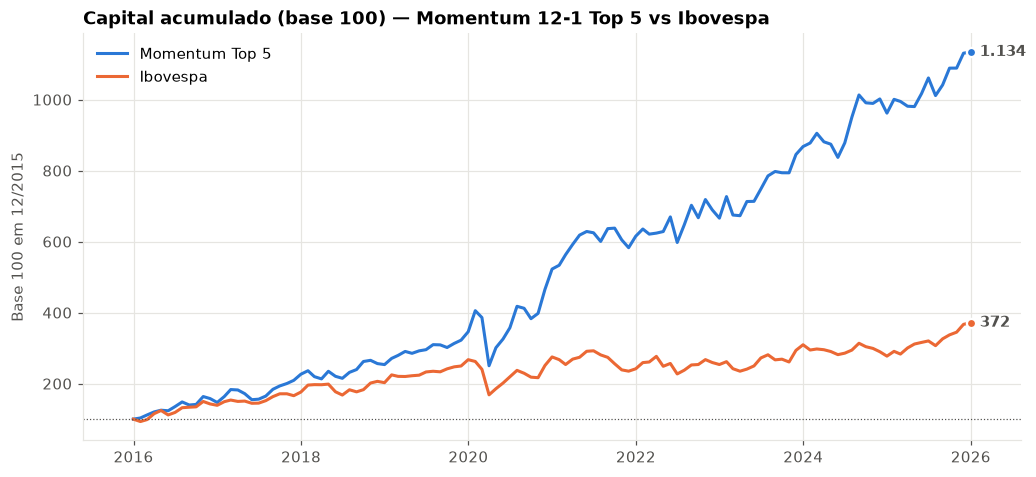

In [13]:
def save_fig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    return path


def label_end(ax, series, color, fmt):
    ax.annotate(fmt(series.iloc[-1]), (series.index[-1], series.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=10, color=C_TEXT, fontweight="bold")
    ax.plot(series.index[-1], series.iloc[-1], "o", color=color, ms=6, mec="white", mew=1.5)


def plot_capital(returns):
    fig, ax = plt.subplots()
    for col, color in zip(returns, [C_PORT, C_IBOV]):
        w = wealth_index(returns[col], 100)
        ax.plot(w.index, w, color=color, label=col)
        label_end(ax, w, color, lambda v: br(f"{v:,.0f}"))
    ax.axhline(100, color=C_TEXT, lw=0.8, ls=":")
    ax.set_title(f"Capital acumulado (base 100) — Momentum 12-1 Top {TOP_N} vs Ibovespa")
    ax.set_ylabel("Base 100 em " + f"{w.index[0]:%m/%Y}")
    ax.legend(loc="upper left")
    ax.margins(x=0.06)
    return fig


fig = plot_capital(returns)
display(Markdown(f"Salvo em `{save_fig(fig, '01_capital_acumulado_base100.png')}`"))
plt.show()

Salvo em `figures\02_drawdown.png`

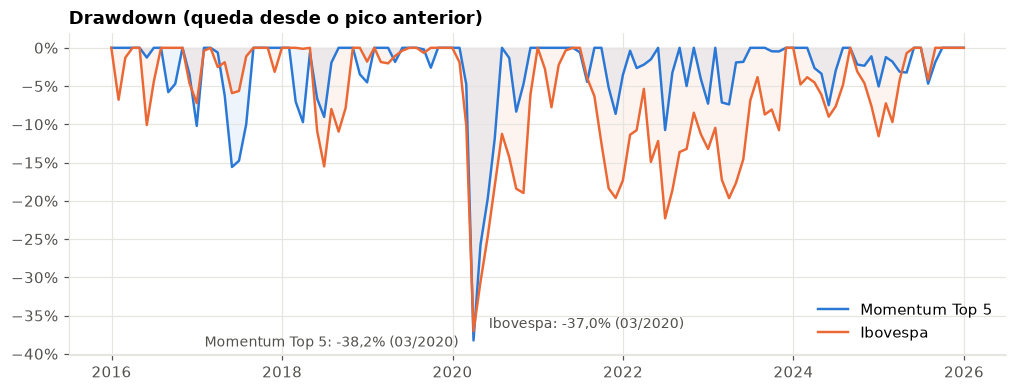

In [14]:
def plot_drawdown(returns):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for col, color, offset in zip(returns, [C_PORT, C_IBOV], [(-10, -4), (10, 2)]):
        dd = drawdown(returns[col])
        ax.plot(dd.index, dd, color=color, label=col, lw=1.6)
        ax.fill_between(dd.index, dd, 0, color=color, alpha=0.08)
        trough = dd.idxmin()
        ax.annotate(f"{col}: {pct(dd.min())} ({trough:%m/%Y})", (trough, dd.min()), xytext=offset,
                    textcoords="offset points", fontsize=9, color=C_TEXT, ha="right" if offset[0] < 0 else "left")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_title("Drawdown (queda desde o pico anterior)")
    ax.legend(loc="lower right")
    return fig


fig = plot_drawdown(returns)
display(Markdown(f"Salvo em `{save_fig(fig, '02_drawdown.png')}`"))
plt.show()

Salvo em `figures\03_retorno_por_ano.png`

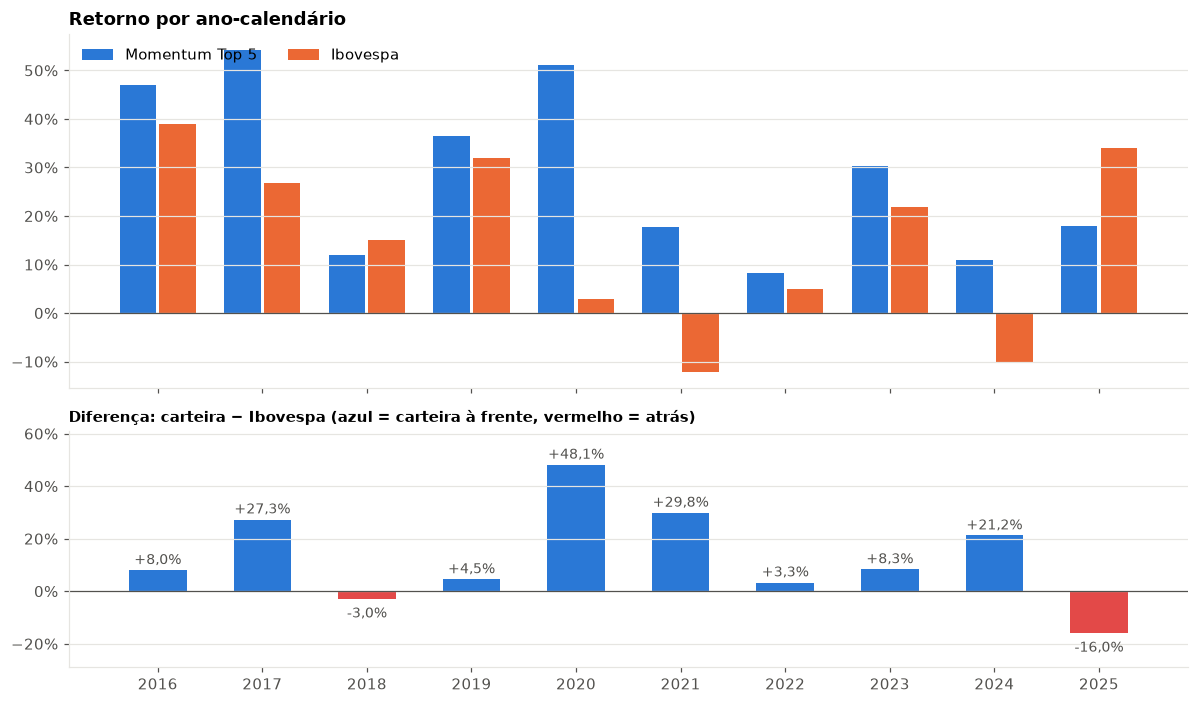

In [15]:
def plot_calendar(yearly):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    x, width = np.arange(len(yearly)), 0.38
    for k, (col, color) in enumerate(zip(yearly.columns[:2], [C_PORT, C_IBOV])):
        ax1.bar(x + (k - 0.5) * width, yearly[col], width - 0.03, color=color, label=col)
    ax1.axhline(0, color=C_TEXT, lw=0.8)
    ax1.set_title("Retorno por ano-calendário")
    ax1.legend(loc="upper left", ncols=2)
    diff = yearly.iloc[:, 2]
    ax2.bar(x, diff, 0.55, color=np.where(diff >= 0, C_PORT, C_NEG))
    for xi, v in zip(x, diff):
        ax2.annotate(pct(v, 1, sign=True), (xi, v), xytext=(0, 4 if v >= 0 else -12), textcoords="offset points",
                     ha="center", fontsize=9, color=C_TEXT)
    ax2.axhline(0, color=C_TEXT, lw=0.8)
    ax2.set_title("Diferença: carteira − Ibovespa (azul = carteira à frente, vermelho = atrás)", fontsize=10)
    ax2.set_xticks(x, yearly.index)
    for ax in (ax1, ax2):
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
        ax.grid(axis="x", visible=False)
    ax2.margins(y=0.2)
    fig.tight_layout()
    return fig


fig = plot_calendar(yearly)
display(Markdown(f"Salvo em `{save_fig(fig, '03_retorno_por_ano.png')}`"))
plt.show()

Salvo em `figures\04_excesso_rolling_12m.png` · Janelas de 12m com carteira atrás do índice: **17%** (18 de 109) · pior janela: **-17,0%** (12m até 09/2019) · melhor janela: **+76,8%** (12m até 03/2021)

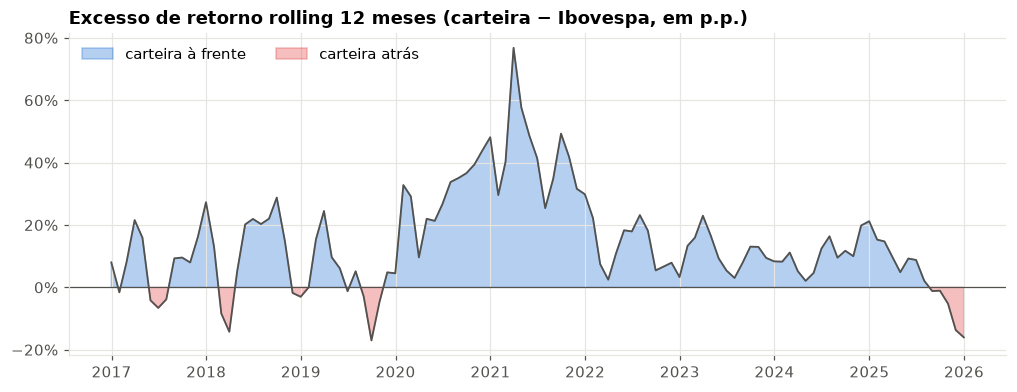

In [16]:
def rolling_return(r, window=12):
    return (1 + r).rolling(window).apply(np.prod, raw=True) - 1


def plot_rolling_excess(returns, window=12):
    excess = (rolling_return(returns.iloc[:, 0], window) - rolling_return(returns.iloc[:, 1], window)).dropna()
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(excess.index, excess, color=C_TEXT, lw=1.2)
    ax.fill_between(excess.index, excess, 0, where=excess >= 0, color=C_PORT, alpha=0.35, interpolate=True,
                    label="carteira à frente")
    ax.fill_between(excess.index, excess, 0, where=excess < 0, color=C_NEG, alpha=0.35, interpolate=True,
                    label="carteira atrás")
    ax.axhline(0, color=C_TEXT, lw=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_title(f"Excesso de retorno rolling {window} meses (carteira − Ibovespa, em p.p.)")
    ax.legend(loc="upper left", ncols=2)
    return fig, excess


fig, rolling_excess = plot_rolling_excess(returns)
display(Markdown(f"Salvo em `{save_fig(fig, '04_excesso_rolling_12m.png')}` · "
                 f"Janelas de 12m com carteira atrás do índice: **{pct((rolling_excess < 0).mean(), 0)}** "
                 f"({(rolling_excess < 0).sum()} de {len(rolling_excess)}) · "
                 f"pior janela: **{pct(rolling_excess.min(), 1, sign=True)}** (12m até {rolling_excess.idxmin():%m/%Y}) · "
                 f"melhor janela: **{pct(rolling_excess.max(), 1, sign=True)}** (12m até {rolling_excess.idxmax():%m/%Y})"))
plt.show()

Salvo em `figures\05_composicao_top5.png`

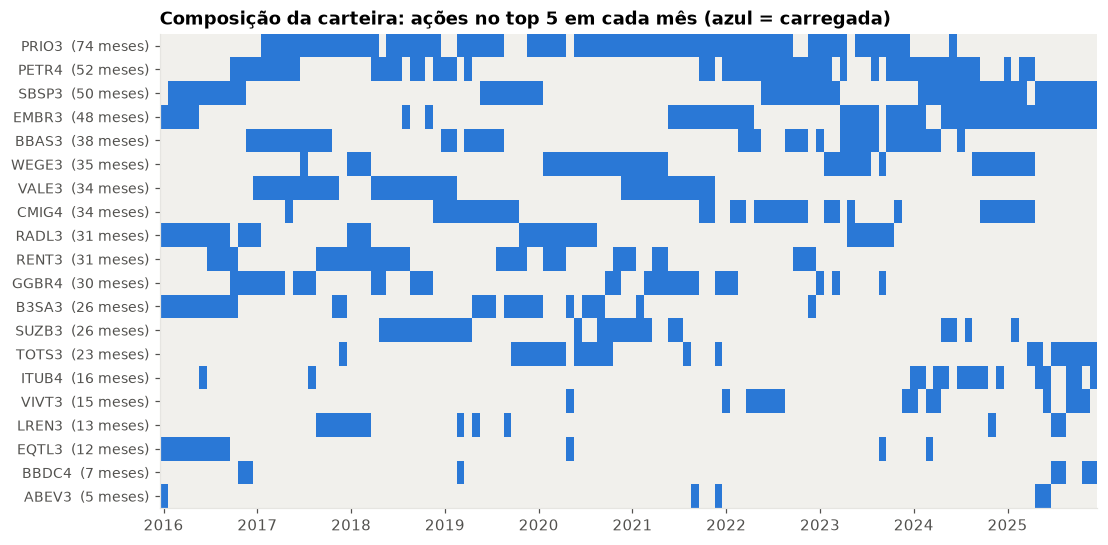

In [17]:
def plot_holdings(held):
    order = held.gt(0).sum().sort_values(ascending=False).index
    grid = held[order].gt(0).astype(int).T
    fig, ax = plt.subplots(figsize=(11, 5.6))
    ax.imshow(grid, aspect="auto", interpolation="none", cmap=ListedColormap(["#f1f0ec", C_PORT]))
    years = grid.columns.year
    ticks = [i for i in range(len(years)) if i == 0 or years[i] != years[i - 1]]
    ax.set_xticks(ticks, [years[i] for i in ticks])
    ax.set_yticks(range(len(order)), [f"{t}  ({n} meses)" for t, n in held[order].gt(0).sum().items()], fontsize=9)
    ax.grid(False)
    ax.set_title(f"Composição da carteira: ações no top {TOP_N} em cada mês (azul = carregada)")
    return fig


fig = plot_holdings(held)
display(Markdown(f"Salvo em `{save_fig(fig, '05_composicao_top5.png')}`"))
plt.show()

## 6. Respostas às perguntas

Antes das respostas, duas análises complementares, também calculadas sobre o backtest.

### Evidência complementar para a pergunta 2: de onde veio o resultado?
Contribuição de cada ação (soma, mês a mês, de peso × retorno) e o mesmo backtest **retirando a PRIO3** do universo.
A PRIO3 é a ação que mais ficou na carteira e, como mostra a seção 1, era uma ação de centavos em 2015–2016.

In [18]:
def contribution_table(held, rets, prices, top=8):
    table = pd.DataFrame({
        "Meses na carteira": held.gt(0).sum(),
        "Contribuição (Σ peso × retorno)": (held * rets.loc[held.index]).sum(),
        f"Preço {held.index[0] - pd.offsets.MonthEnd(1):%m/%Y}": prices.loc[held.index[0] - pd.offsets.MonthEnd(1)],
        f"Preço {held.index[-1]:%m/%Y}": prices.loc[held.index[-1]],
    }).sort_values("Contribuição (Σ peso × retorno)", ascending=False)
    total = table["Contribuição (Σ peso × retorno)"].sum()
    table["% da contribuição total"] = table["Contribuição (Σ peso × retorno)"] / total
    return table.head(top)


contrib = contribution_table(held, stock_rets, stock_prices)
shown = format_pct(contrib, ["Contribuição (Σ peso × retorno)", "% da contribuição total"])
for c in contrib.columns[2:4]:
    shown[c] = contrib[c].map(lambda x: br(f"{x:.2f}"))
display(shown)

ret_ex_prio = backtest(top_n_weights(momentum_12_1(stock_prices.drop(columns="PRIO3")), TOP_N),
                       stock_rets, ANALYSIS_START, ANALYSIS_END)
sensitivity = performance_table(pd.DataFrame({"Momentum Top 5 (20 ações)": port_ret, "Momentum Top 5 sem PRIO3": ret_ex_prio,
                                              "Ibovespa": bench_ret}), "Ibovespa", cdi)
display(format_metrics(sensitivity.loc[["Retorno anualizado (CAGR)", "Volatilidade anualizada", "Sharpe (rf = 0)",
                                        "Sharpe (rf = CDI)", "Máximo drawdown"], sensitivity.columns[:3]]))

,Meses na carteira,Contribuição (Σ peso × retorno),Preço 12/2015,Preço 12/2025,% da contribuição total
PRIO3,74,"88,3%","0,24","41,42","32,2%"
SBSP3,50,"27,8%","2,81","26,49","10,1%"
PETR4,52,"24,7%","1,68","28,98","9,0%"
B3SA3,26,"22,0%","2,48","13,09","8,0%"
EMBR3,48,"18,8%","28,88","88,08","6,9%"
BBAS3,38,"17,3%","3,87","21,42","6,3%"
TOTS3,23,"15,1%","8,83","41,43","5,5%"
VALE3,34,"13,3%","6,27","70,00","4,9%"


,Momentum Top 5 (20 ações),Momentum Top 5 sem PRIO3,Ibovespa
Retorno anualizado (CAGR),"27,5%","19,1%","14,0%"
Volatilidade anualizada,"23,5%","20,5%","21,7%"
Sharpe (rf = 0),"1,17","0,96","0,72"
Sharpe (rf = CDI),"0,78","0,52","0,31"
Máximo drawdown,"-38,2%","-31,7%","-37,0%"


### Evidência complementar para a pergunta 3
Para não responder só com teoria, a célula abaixo compara o **12-1** com um **12-0** (mesma regra, mas usando o preço de t,
sem pular o mês) e mede, mês a mês, a correlação de ranking (Spearman, *IC*) entre o retorno do mês t e o do mês t+1
dentro do universo. Aqui o `shift(-1)` é usado **só para avaliar** a relação; ele não entra em nenhuma decisão da carteira.

In [19]:
def momentum_12_0(prices):
    return prices / prices.shift(12) - 1


def rank_ic(signal, next_rets):
    ic = signal.rank(axis=1).corrwith(next_rets.rank(axis=1), axis=1).dropna()
    return pd.Series({"IC médio": ic.mean(), "t-stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
                      "% meses IC > 0": (ic > 0).mean(), "Meses": len(ic)})


period = slice(ANALYSIS_START, ANALYSIS_END)
next_rets = stock_rets.shift(-1)              # avaliação apenas: retorno do mês seguinte ao sinal
formation = stock_rets.loc[period].index - pd.offsets.MonthEnd(1)

ret_12_0 = backtest(top_n_weights(momentum_12_0(stock_prices), TOP_N), stock_rets, ANALYSIS_START, ANALYSIS_END)
skip_compare = performance_table(pd.DataFrame({"12-1 (pula o último mês)": port_ret, "12-0 (inclui o último mês)": ret_12_0,
                                               "Ibovespa": bench_ret}), "Ibovespa", cdi)
display(format_metrics(skip_compare.loc[["Retorno anualizado (CAGR)", "Volatilidade anualizada", "Sharpe (rf = 0)",
                                         "Sharpe (rf = CDI)", "Máximo drawdown"], skip_compare.columns[:3]]))

ic_table = pd.DataFrame({
    "Retorno do último mês (t) → retorno de t+1": rank_ic(stock_rets.loc[formation], next_rets.loc[formation]),
    "Momentum 12-1 (t) → retorno de t+1": rank_ic(mom.loc[formation], next_rets.loc[formation]),
}).T
ic_table["IC médio"] = ic_table["IC médio"].map(lambda x: br(f"{x:+.3f}"))
ic_table["t-stat"] = ic_table["t-stat"].map(lambda x: br(f"{x:+.2f}"))
ic_table["% meses IC > 0"] = ic_table["% meses IC > 0"].map(lambda x: pct(x, 0))
ic_table["Meses"] = ic_table["Meses"].astype(int)
display(ic_table)

,12-1 (pula o último mês),12-0 (inclui o último mês),Ibovespa
Retorno anualizado (CAGR),"27,5%","31,1%","14,0%"
Volatilidade anualizada,"23,5%","23,3%","21,7%"
Sharpe (rf = 0),"1,17","1,30","0,72"
Sharpe (rf = CDI),"0,78","0,91","0,31"
Máximo drawdown,"-38,2%","-35,7%","-37,0%"


,IC médio,t-stat,% meses IC > 0,Meses
Retorno do último mês (t) → retorno de t+1,"+0,047","+1,93",56%,120
Momentum 12-1 (t) → retorno de t+1,"+0,012","+0,37",52%,120


### Pergunta 1 — A estratégia bateu o Ibovespa ajustado ao risco? Em que períodos falhou?

**Sim, neste backtest e com folga.** De jan/2016 a dez/2025 (120 meses):

| | Carteira | Ibovespa |
|---|---|---|
| Retorno anualizado | 27,5% | 14,0% |
| Volatilidade | 23,5% | 21,7% |
| Sharpe (rf = 0) | 1,17 | 0,72 |
| Sharpe (rf = CDI) | 0,78 | 0,31 |
| Máximo drawdown | −38,2% | −37,0% |

A carteira teve volatilidade só 1,8 p.p. maior e um drawdown máximo praticamente igual ao do índice, mas quase dobrou o retorno
anualizado. Base 100 virou 1.134 contra 372 do Ibovespa. Com o CDI como taxa livre de risco, que é a comparação relevante no Brasil
(o CDI rendeu 9,3% a.a. no período), o Sharpe da carteira foi **2,5 vezes** o do índice. O information ratio de 0,72 em 10 anos
equivale a uma estatística t de cerca de 2,3 (0,72 × √10), e a carteira ficou à frente do índice em 62,5% dos meses.
Ela ficou à frente em **8 dos 10 anos-calendário**, com os maiores ganhos em 2020 (+48,1 p.p.), 2021 (+29,8 p.p.), 2017 (+27,3 p.p.) e
2024 (+21,2 p.p.). Em 2021 e 2024, o índice caiu (−12,1% e −10,4%) e a carteira subiu.

**Onde falhou:**
- **2025: o pior ano relativo (−16,0 p.p.; 17,9% contra 34,0%).** A carteira ficou abaixo do índice em 8 dos 12 meses (mar/2025: −1,4%
  contra +6,1%) porque passou o ano carregando os vencedores de 2024 (EMBR3 nos 12 meses, SBSP3 e TOTS3). Depois de um 2024 negativo,
  o mercado virou para uma alta ampla, e o sinal de 12 meses demora a girar. É o padrão clássico de momentum em **viradas de mercado
  após quedas**. A janela de 12 meses até dez/2025 é uma das piores do backtest (−16,0 p.p.).
- **Janela de 12 meses até set/2019 (−17,0 p.p., a pior do backtest)** e **2018 (−3,0 p.p. no ano).** A carteira estava concentrada em
  exportadoras e commodities (PETR4, VALE3, SUZB3, GGBR4, PRIO3). Em out/2018, mês da eleição, o Ibovespa subiu 10,2% e a carteira
  só 1,3%. Em jan/2019 foram 10,8% contra 6,9%.
- **Janela de 12 meses até mar/2018 (−14,2 p.p.):** no rali de jan/2018 o índice subiu 11,1% e a carteira 4,4%. Em fev/2018 foram
  0,7% contra −7,0%.
- **Crash da COVID (mar/2020):** a carteira caiu 35,2% no mês contra 29,9% do índice, porque os vencedores de 12 meses (PRIO3 −57,6%,
  RENT3 −46,8%, TOTS3 −34,3%) caíram mais. Esse é o maior drawdown da estratégia (−38,2%, pico em jan/2020). A diferença é que a carteira
  recuperou o pico em **jul/2020 (6 meses)**, enquanto o Ibovespa levou até dez/2020. No longo drawdown do índice de jun/2021 a nov/2023
  (−22,3%, 29 meses), a carteira caiu no máximo 10,8%.
- No total, a carteira ficou atrás do índice em **18 das 109 janelas móveis de 12 meses (17%)**, concentradas em meados de 2017,
  2018–2019 e no 2º semestre de 2025.

**Ressalva importante:** o resultado depende muito de uma ação. Sem a PRIO3 no universo, o CAGR cai de 27,5% para 19,1% e o Sharpe com
CDI cai de 0,78 para 0,52. Ainda é melhor que o Ibovespa (0,31), mas a vantagem cai pela metade. Além disso, o IC médio do sinal 12-1 em
todo o universo é quase zero (+0,012, t = 0,37). O sinal acertou os vencedores extremos, mas não ordenou bem as 20 ações em geral.
Junto com o viés da pergunta 2, isso indica que **o desempenho passado é um limite superior**, não uma expectativa.

### Pergunta 2 — Que viés o universo escolhido hoje introduz no resultado?

**Viés de sobrevivência e de seleção, que é uma forma de look-ahead na escolha do universo.** As 20 ações foram escolhidas porque
**hoje** são grandes, líquidas e sobreviveram. Em jan/2016, ninguém montaria esse universo sem saber o futuro.

- **Exemplo concreto deste backtest: a PRIO3.** Em dez/2015 ela valia **R$ 0,24** (preço ajustado). Era a PetroRio, uma ação de
  centavos e baixa liquidez, com dias de variação acima de 80% (tabela da seção 1). Em dez/2025 valia **R$ 41,42**, cerca de 170 vezes mais.
  Ela só está no universo porque se tornou uma grande empresa. Foi a ação mais carregada (74 de 120 meses) e respondeu por **32% de toda a
  contribuição** da carteira. Retirá-la tira 8,4 p.p. de retorno anualizado.
- **O lado oposto também está ausente:** empresas que eram grandes em 2016 e depois desabaram ou saíram da bolsa (por exemplo, Americanas
  após a fraude de 2023, Cielo, que fechou o capital em 2024, ou Cogna, ex-Kroton, que perdeu a maior parte do valor). Nenhuma delas pode
  entrar no top 5 deste backtest, nem nos meses em que tiveram momentum alto antes de cair.
- **Por que isso infla especialmente uma estratégia de momentum:** quem vira empresa grande hoje é, quase por definição, quem teve retornos
  altos e persistentes no passado, ou seja, quem teve momentum. O universo já vem filtrado pelos vencedores do período testado.
- **Comparação assimétrica:** o Ibovespa é *point-in-time* (sua composição muda a cada quadrimestre e inclui as empresas que depois caíram),
  enquanto a carteira escolhe entre sobreviventes. Parte do excesso de retorno vem dessa diferença e não do sinal.

**Como corrigir:** usar um **universo point-in-time**, por exemplo a composição histórica do Ibovespa em cada data de rebalanceamento,
ou um filtro de liquidez e tamanho aplicado só com dados disponíveis em t. Também é preciso incluir as empresas que saíram da bolsa, com seus
retornos até a saída, usando uma base que as preserve (Economatica, ComDinheiro, histórico da B3).

### Pergunta 3 — Por que pular o último mês na formação do sinal?

**O argumento teórico:** no horizonte de 1 mês, as ações costumam mostrar **reversão de curto prazo**, ou seja, quem subiu muito no mês
tende a devolver parte no mês seguinte (Jegadeesh, 1990). Isso vem sobretudo de microestrutura e liquidez: *bid-ask bounce*, pressão
temporária de compra e venda e sobrerreação a notícias. Esse efeito tem sinal **oposto** ao momentum de médio prazo (3 a 12 meses, Jegadeesh
e Titman, 1993). Se o mês t entrasse no sinal, o ranking misturaria dois efeitos contrários. Pular o mês, usando $P_{t-1}/P_{t-12}$,
isola a **continuação de médio prazo**, que é o efeito que a estratégia quer capturar. Também reduz o giro gerado por ruído do último mês.

**O que os dados deste case mostram (evidência na célula acima): aqui a reversão de 1 mês não apareceu.**
- O 12-0, que inclui o último mês, teve CAGR de 31,1% e Sharpe de 1,30 (rf = 0), contra 27,5% e 1,17 do 12-1.
- O IC entre o retorno do mês t e o do mês t+1 foi **positivo** (+0,047, t = 1,93, com 56% dos meses positivos). Isso indica uma leve
  **continuação**, não reversão, nessas 20 ações em 2016–2025.

Isso não invalida a escolha do 12-1. A reversão de curto prazo é mais forte em ações pequenas e ilíquidas, e o universo aqui são 20
*blue chips*, onde o *bid-ask bounce* é pequeno. A amostra (20 ações, 120 meses) é curta demais para distinguir uma diferença de 0,13 de
Sharpe de ruído. E trocar para 12-0 **porque rendeu mais neste backtest** seria ajustar a regra aos dados (*overfitting*). O 12-1 é a
especificação definida *ex ante*, com evidência fora da amostra em vários mercados e décadas. Por isso deve ser mantido, registrando
que neste universo específico o benefício de pular o mês não se confirmou.

## 7. Limitações

- **Sem custos de transação, impostos e slippage.** O giro médio calculado na seção 3 indica quantas ações trocam por mês.
  Com corretagem, emolumentos, spread e IR sobre ganhos (15% em swing trade), o retorno líquido seria menor que o reportado.
- **Viés de sobrevivência e seleção** (pergunta 2): o universo foi escolhido com o conhecimento de hoje. O resultado deve ser lido como
  um **limite superior**, e não como uma estimativa do que seria obtido em tempo real.
- **Universo pequeno (20 ações)** e concentrado em poucos setores. Um top 5 de 20 é um quartil grosseiro, e o ranking é ruidoso.
  Uma ação sozinha pesa 20% da carteira e pode dominar o resultado.
- **Pesos iguais e rebalanceamento mensal** sem considerar liquidez, volatilidade ou limites setoriais. Em 2015–2016, algumas ações
  do universo (por exemplo, a PRIO3) tinham liquidez que tornaria difícil executar o volume de uma carteira real.
- **Só 10 anos (120 meses).** Isso é pouco para separar sorte de habilidade: um Sharpe da ordem de 0,5 tem erro-padrão de cerca de
  0,3 nesse horizonte ($\approx\sqrt{1/10}$ ao ano).
  O período também cobre poucos regimes de mercado (um rali de 2016–2019, um crash em 2020 e juros altos em 2022–2025).
- **Qualidade dos dados do Yahoo:** preços ajustados podem ter erros pontuais de proventos. A EMBR3 depende do histórico sob o código
  novo (EMBJ3), e o momento exato da execução (fechamento do último pregão do mês) é uma idealização.
- **Benchmark:** o Ibovespa é um índice de retorno total (reinveste proventos), assim como os preços ajustados, então a comparação é justa
  nesse aspecto. Mas o índice não paga custos, e a carteira também não foi cobrada por eles.